In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pylabdd as dd

In [2]:
maxout = 1000
par_list = [(0.3, 600), (0.3, 900), (3, 600), (3, 900)]
Np = len(par_list)
bdmax = np.zeros((Np, maxout))
btot = np.zeros((Np, maxout))
sim_time = np.zeros((Np, maxout))
nit = np.zeros(Np, dtype=int)
Ngb_list = np.zeros(Np, dtype=int)
lgb_list = np.zeros(Np)
temp_list = np.zeros(Np)

In [ ]:
# Run simulation only if necessary
tau0 = 0.0
grain_size = 1.0
niter = 500_000_000
delta = 0.004
dtmax = 6.25e-7/delta**4  # value 1.e4 for delta=0.005, 50. for PU
for i, (lgb, temp) in enumerate(par_list):
    ngbn = int(lgb/delta)
    if ngbn % 2 == 0: ngbn += 1
    tfin = 5.e9*(lgb/0.3)*(900/temp)**5
    print(f"Simulation with N_gbn={ngbn}, delta={delta}, dtmax={dtmax}")
    gbdd = dd.GB_dislocations(temp=temp, tau0=tau0,
                       Ngbn=ngbn, len_gb_seg=lgb, grain_size=grain_size,
                       tfin=tfin, niter=niter, maxout=maxout,
                       dtmax=dtmax,
                       screenout=True)
    gbdd.run_sim()
    gbdd.save_hdf5(f"gb1_T{int(temp)}_H{int(gs*10)}_L{int(lgb*10)}.h5")
    gbdd.plot_time_series(['timestep', 'n_gbdis_eff'])
    #gbdd.plot_time_series('max_bdot')
    gbdd.plot_field('displacement')
    #gbdd.plot_field('flux')
    nit[i] = gbdd.nout
    Ngb_list[i] = gbdd.Ngbn
    sim_time[i, 0:gbdd.nout] = gbdd.sim_time
    bdmax[i, 0:gbdd.nout] = gbdd.glob_data['max_bdot']
    btot[i, 0:gbdd.nout] = gbdd.glob_data['n_gbdis_eff']

Data file with temp=600.0, Lgb=0.3, dtmax=1000000.0


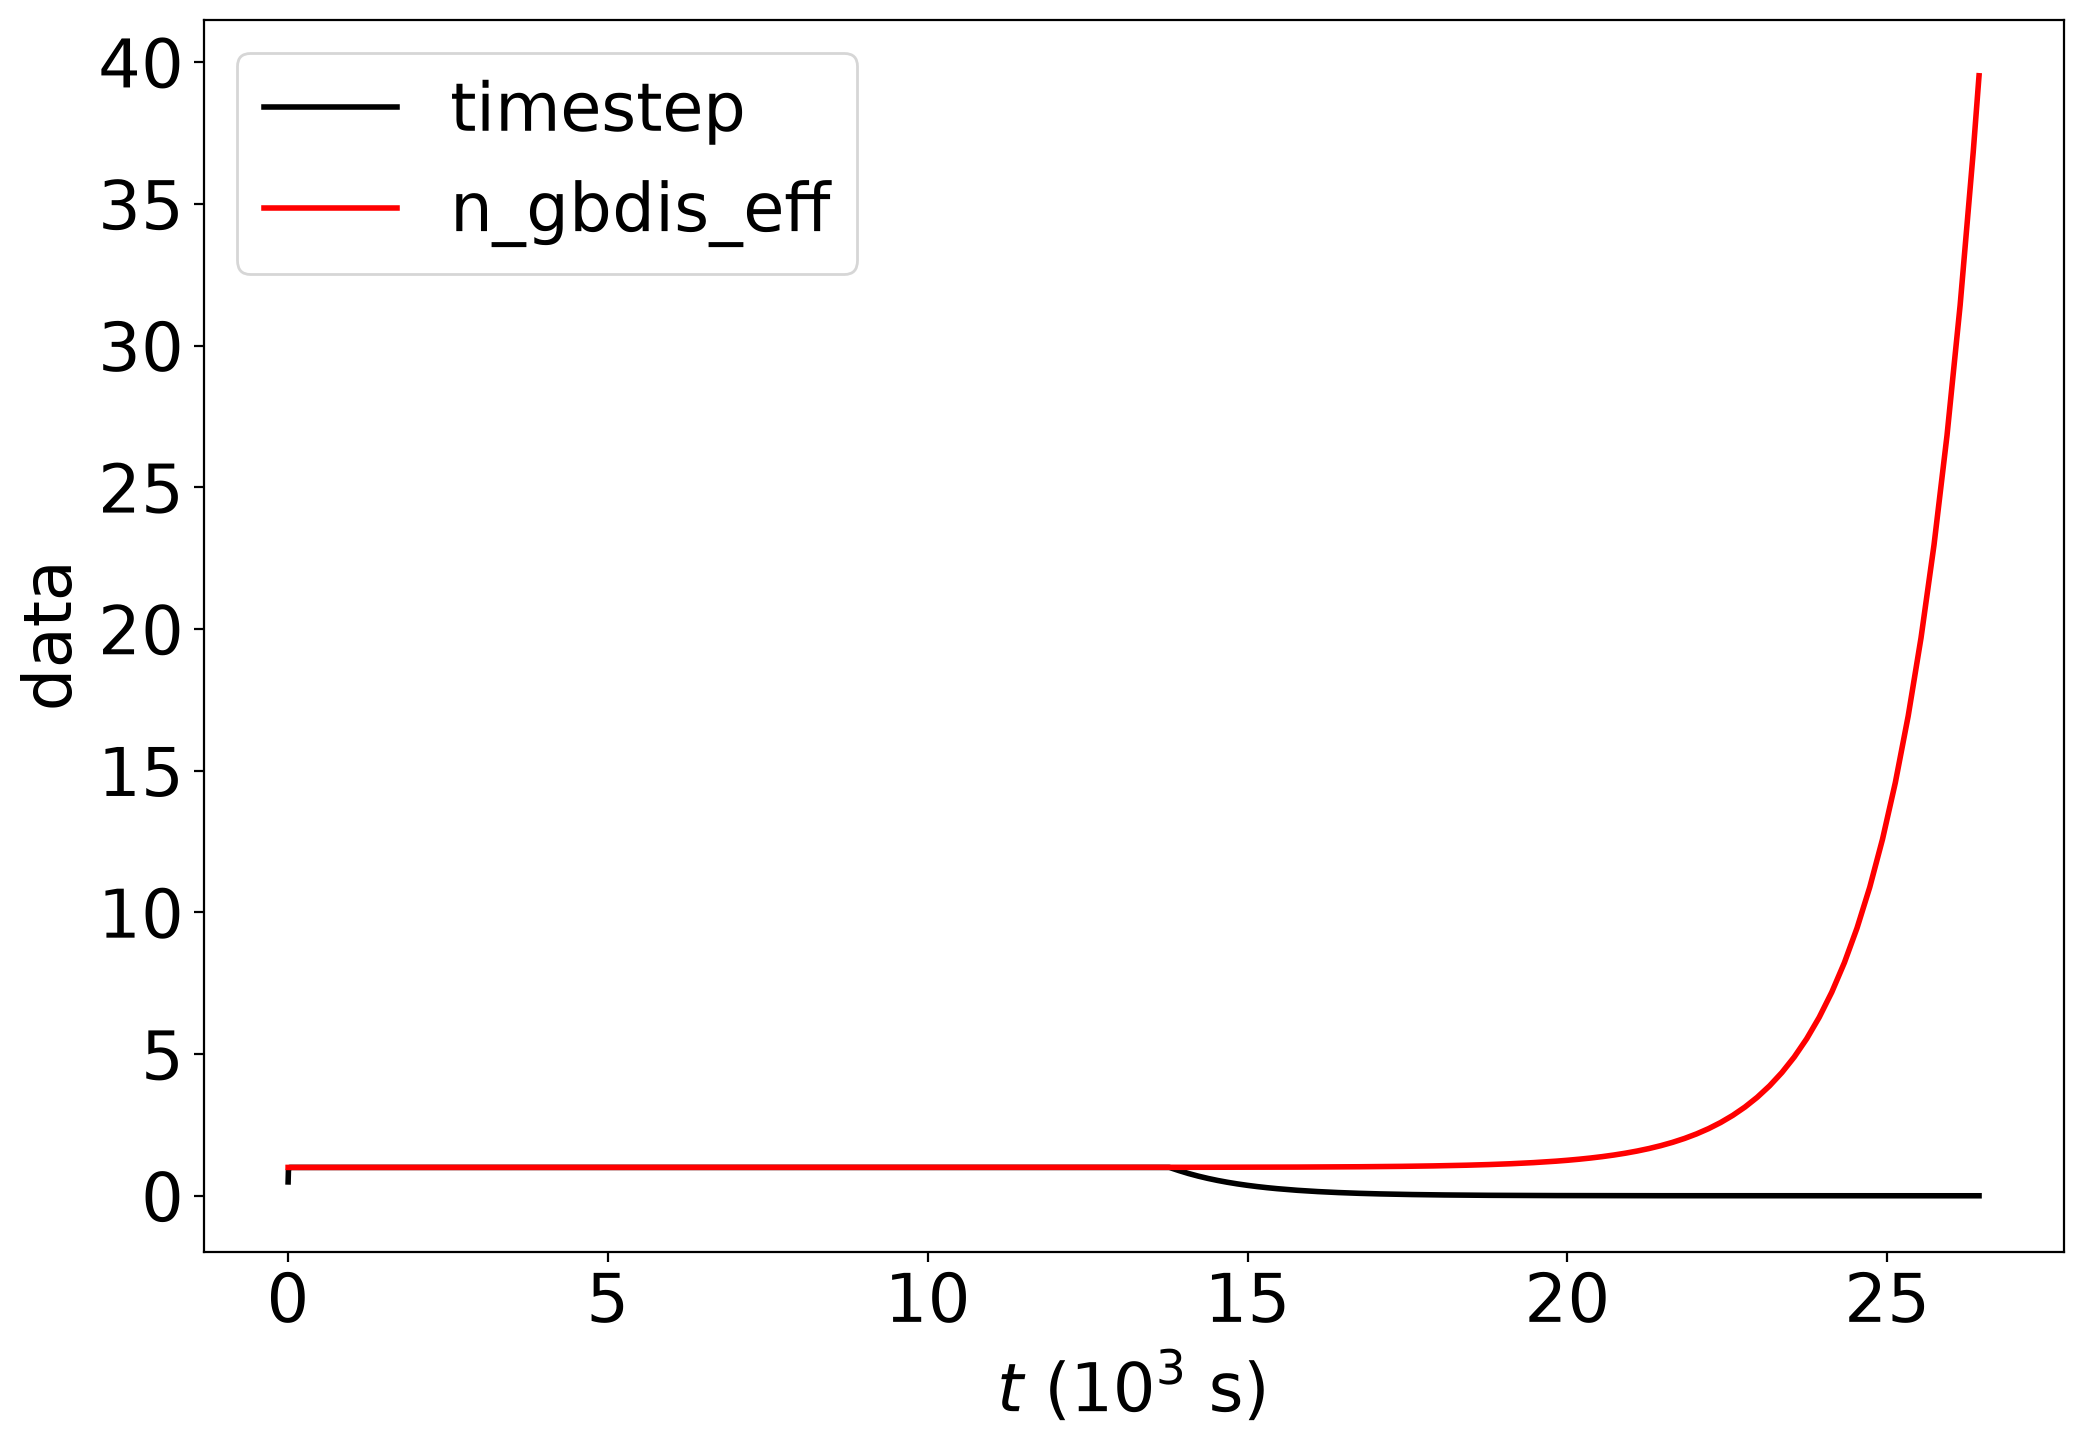

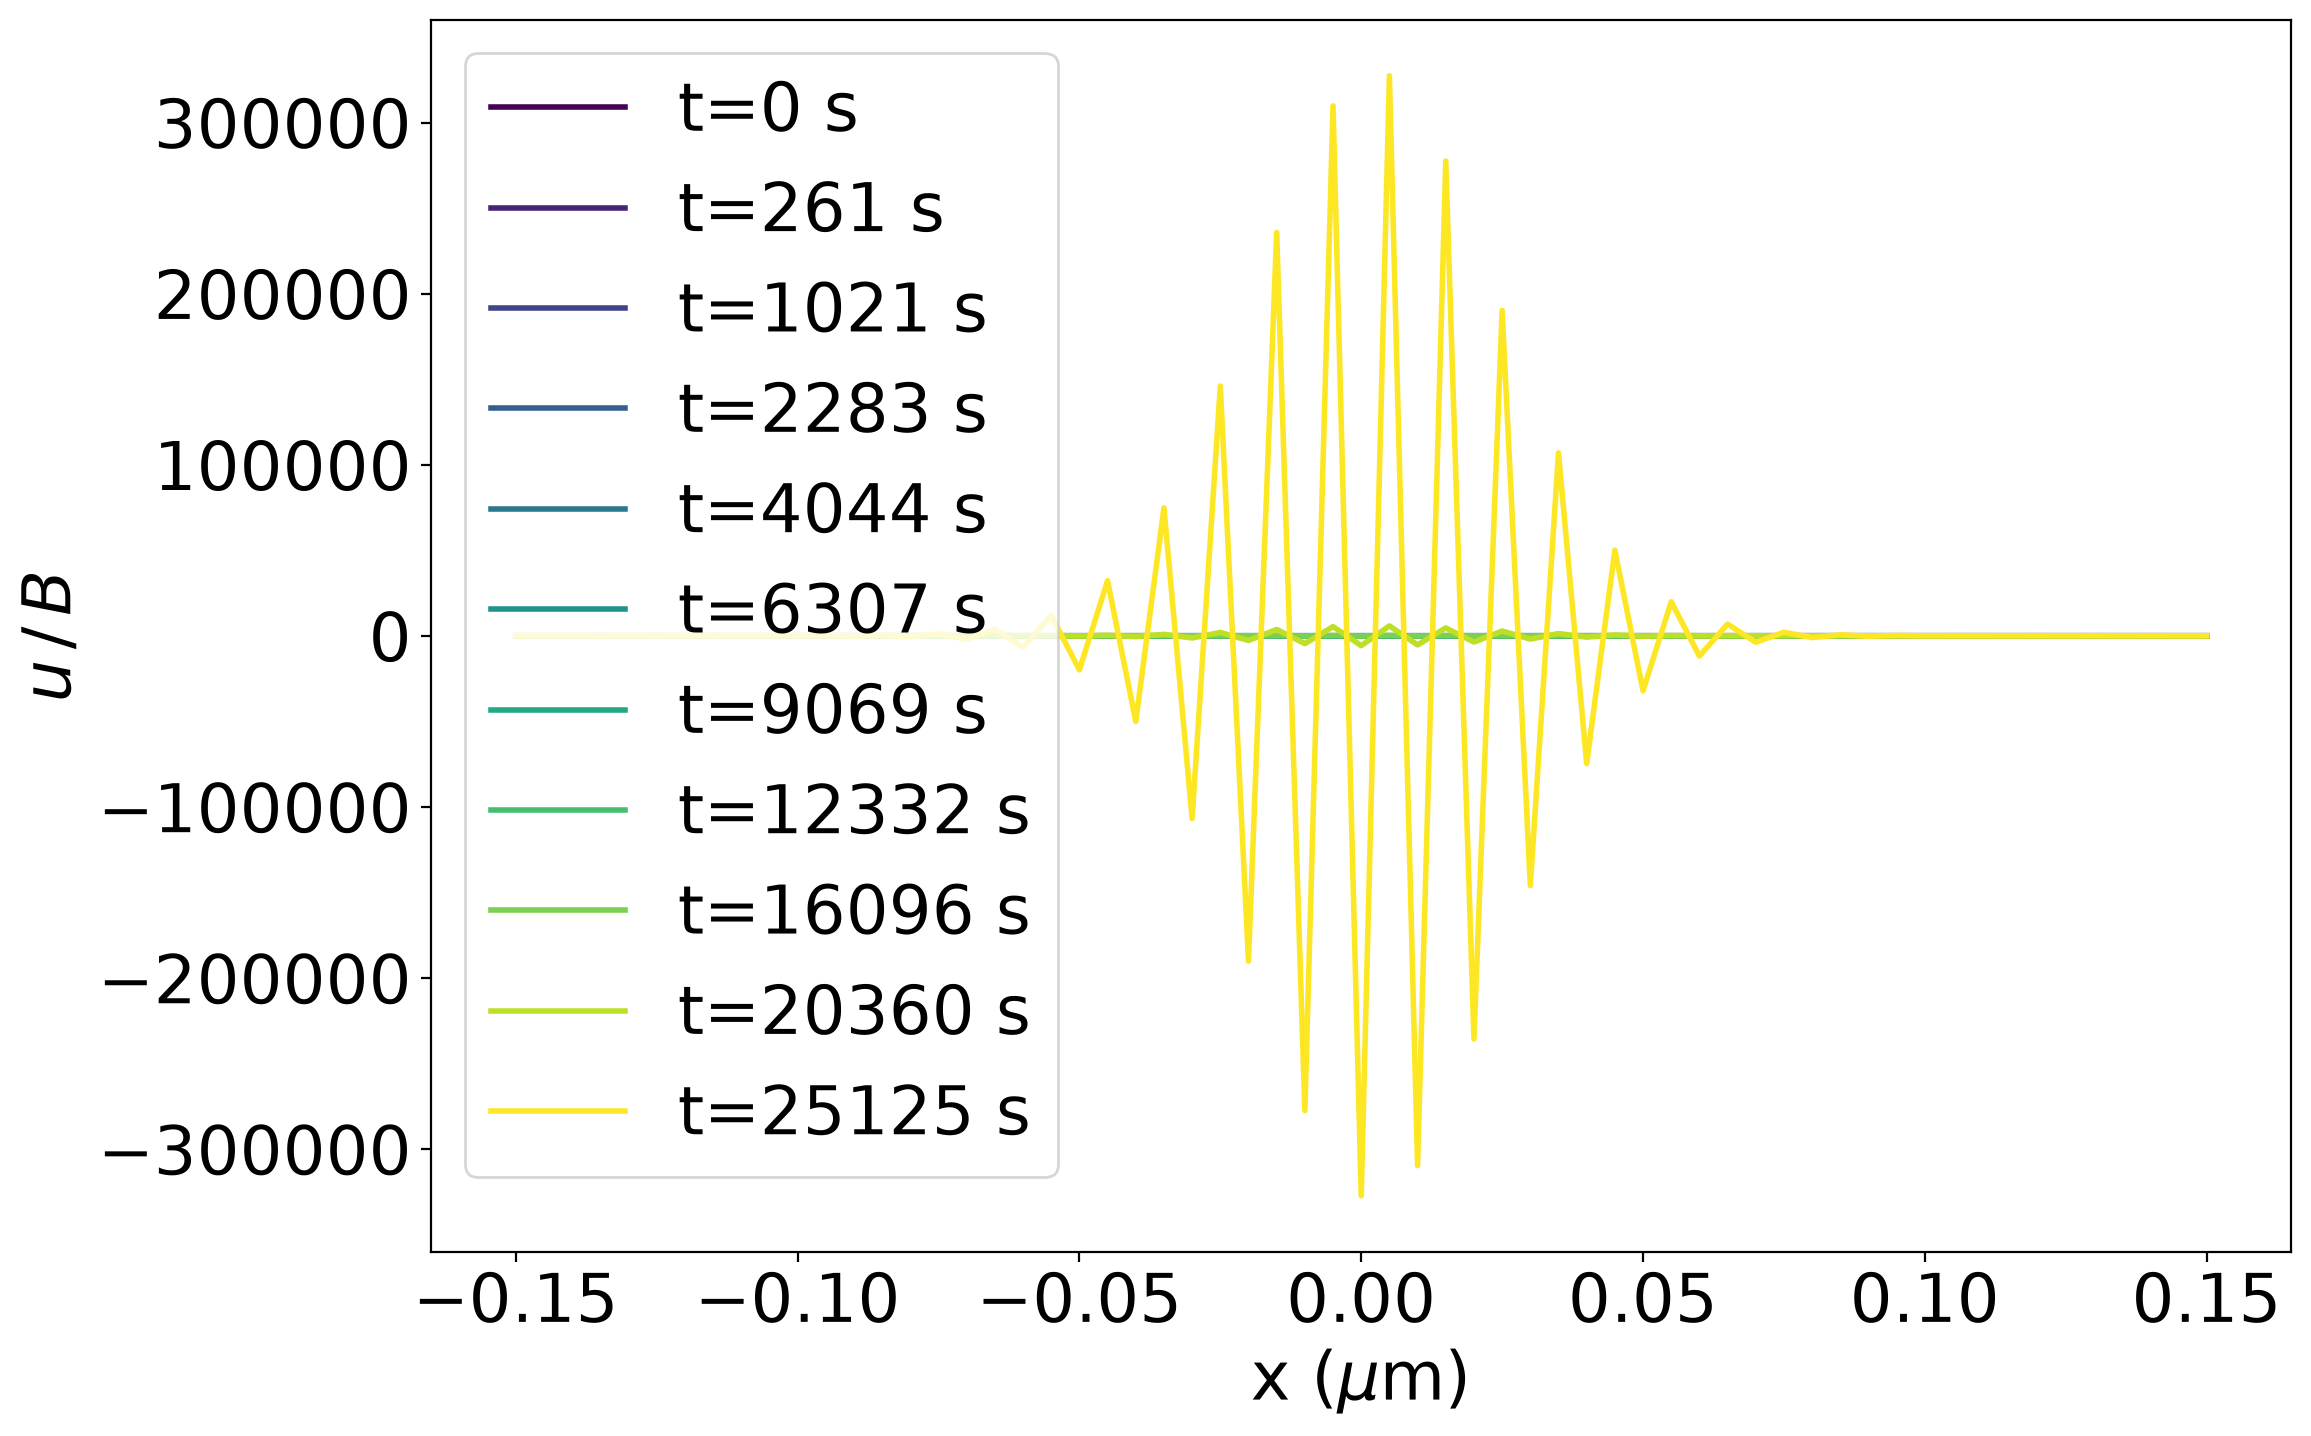

Data file with temp=900.0, Lgb=0.3, dtmax=100000.0


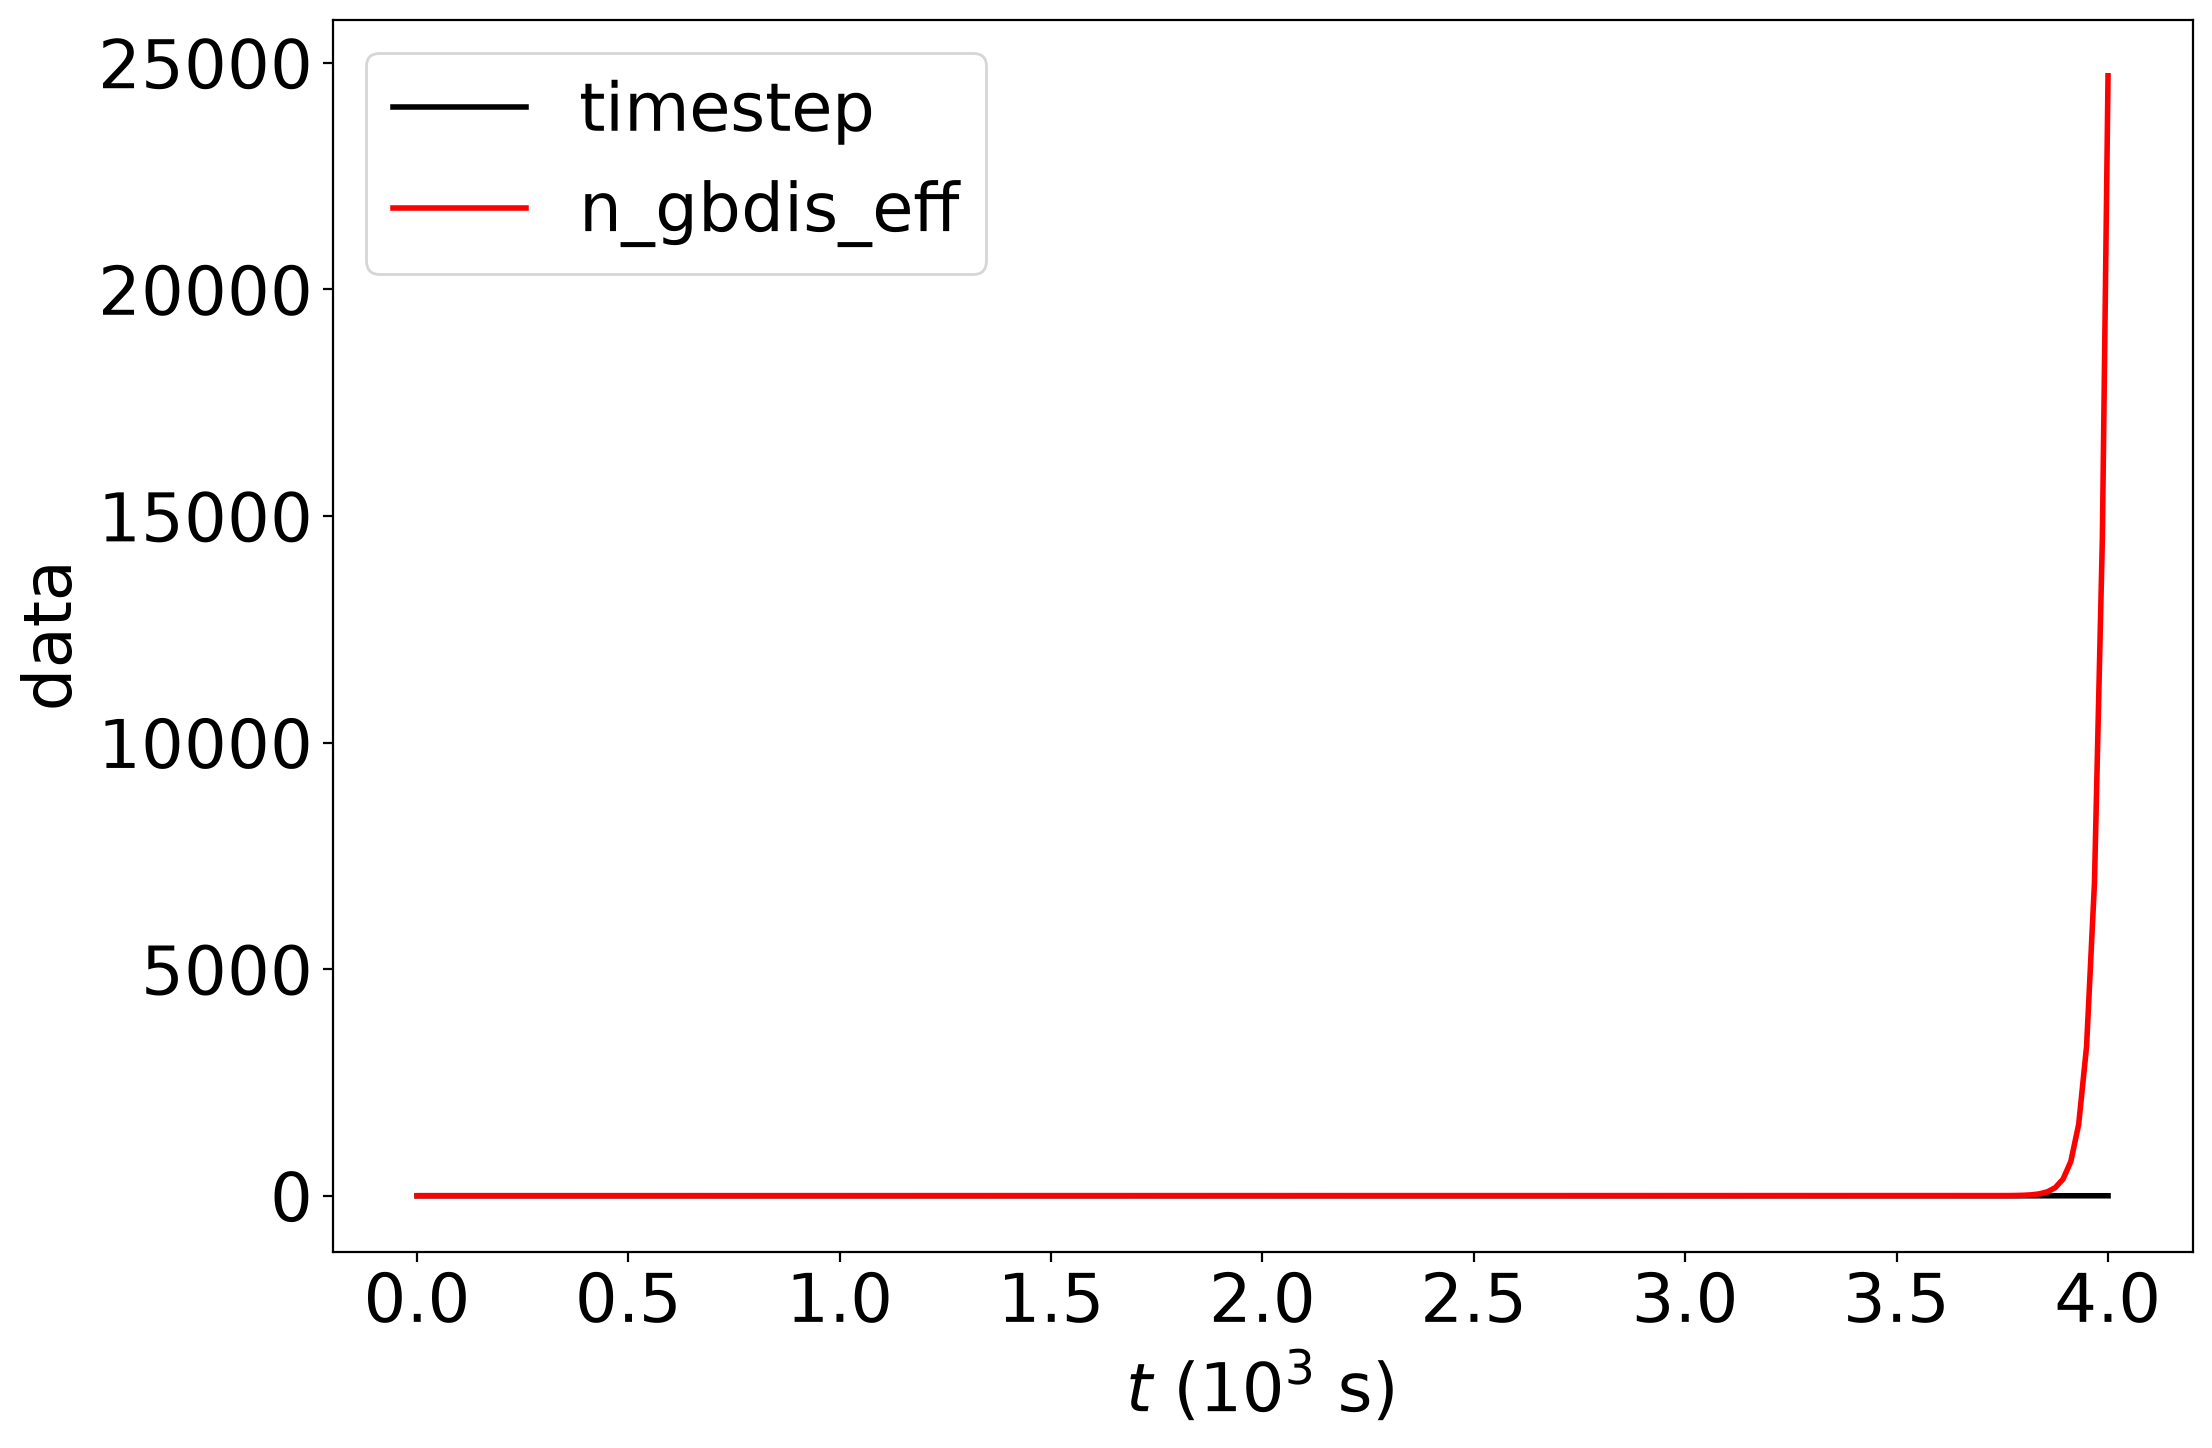

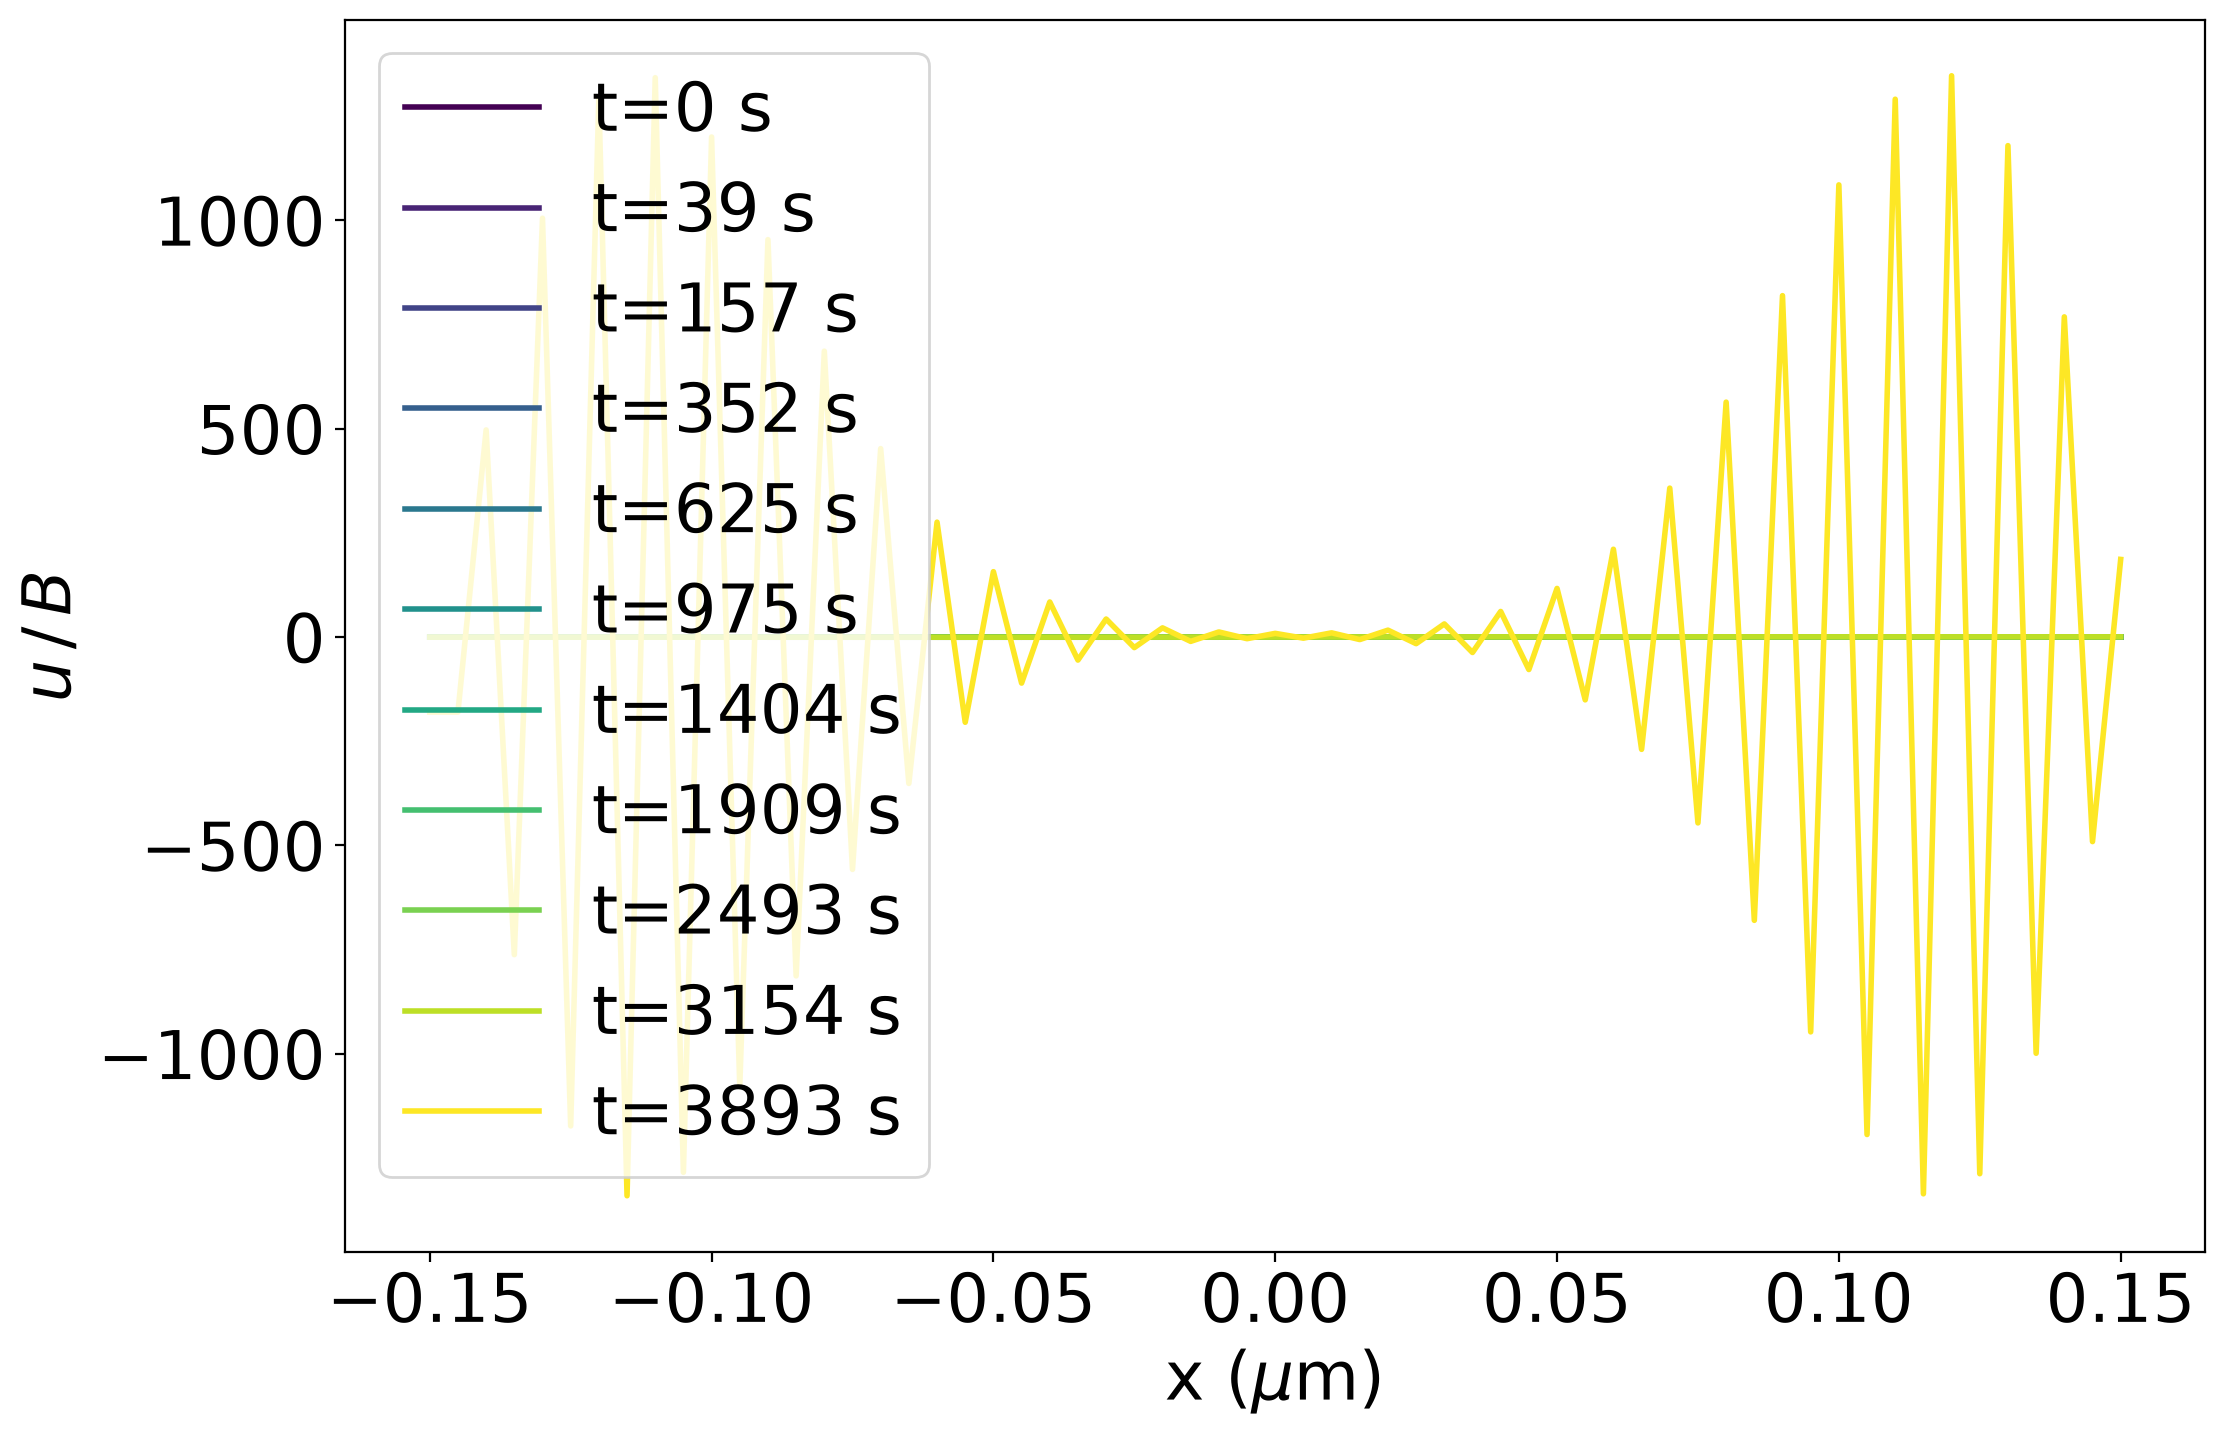

Data file with temp=600.0, Lgb=3.0, dtmax=1000000.0


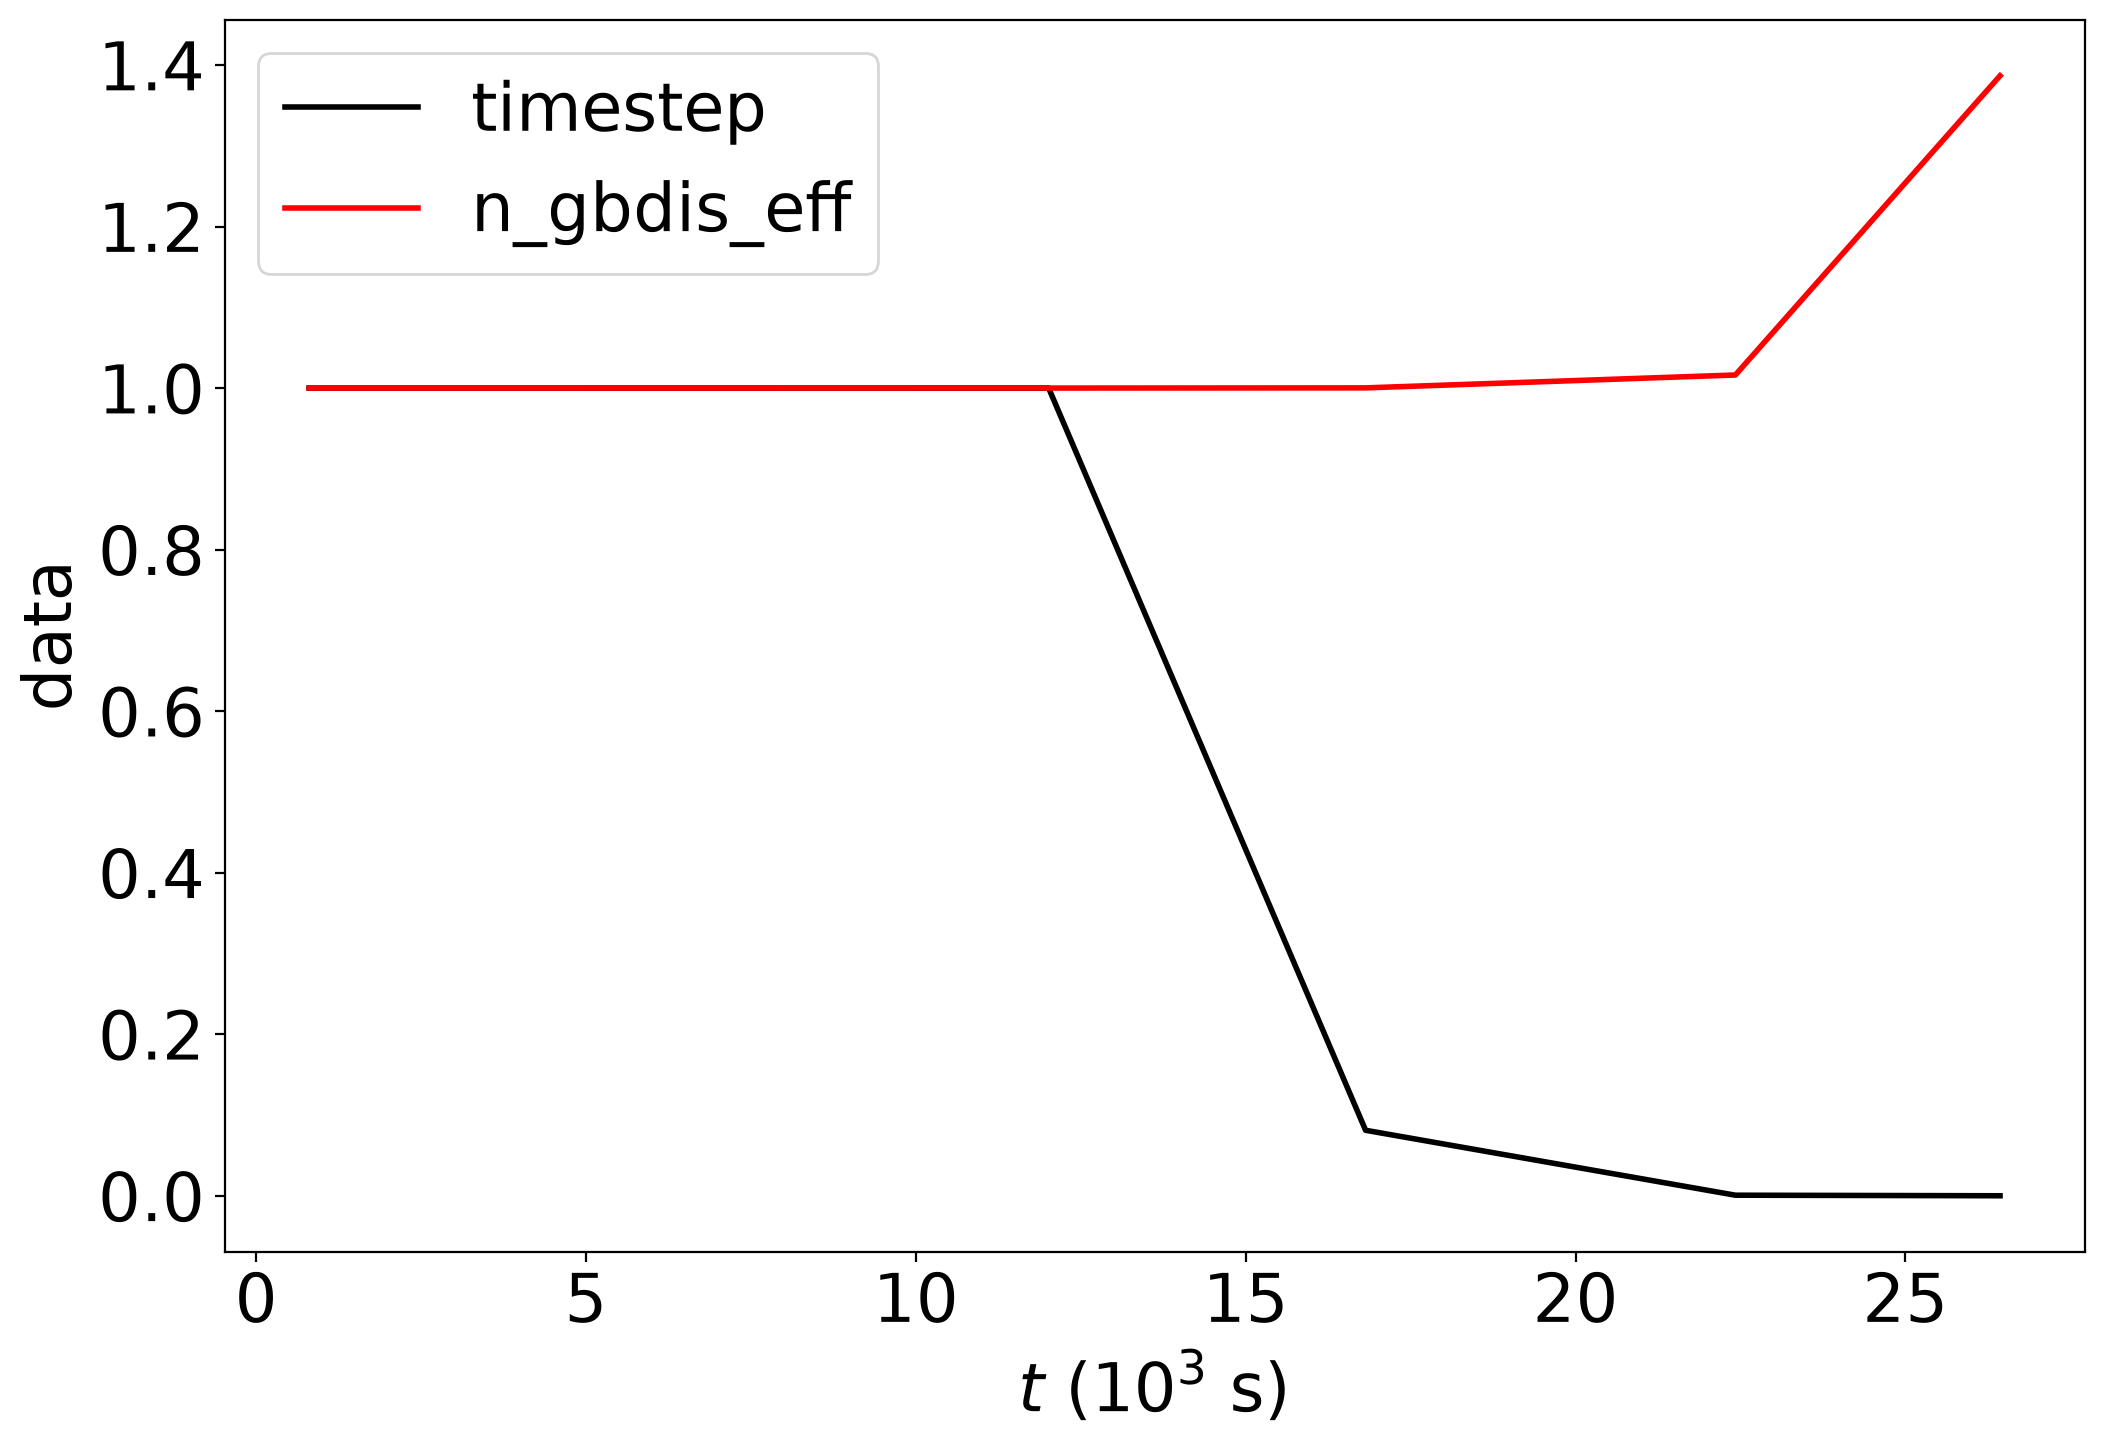

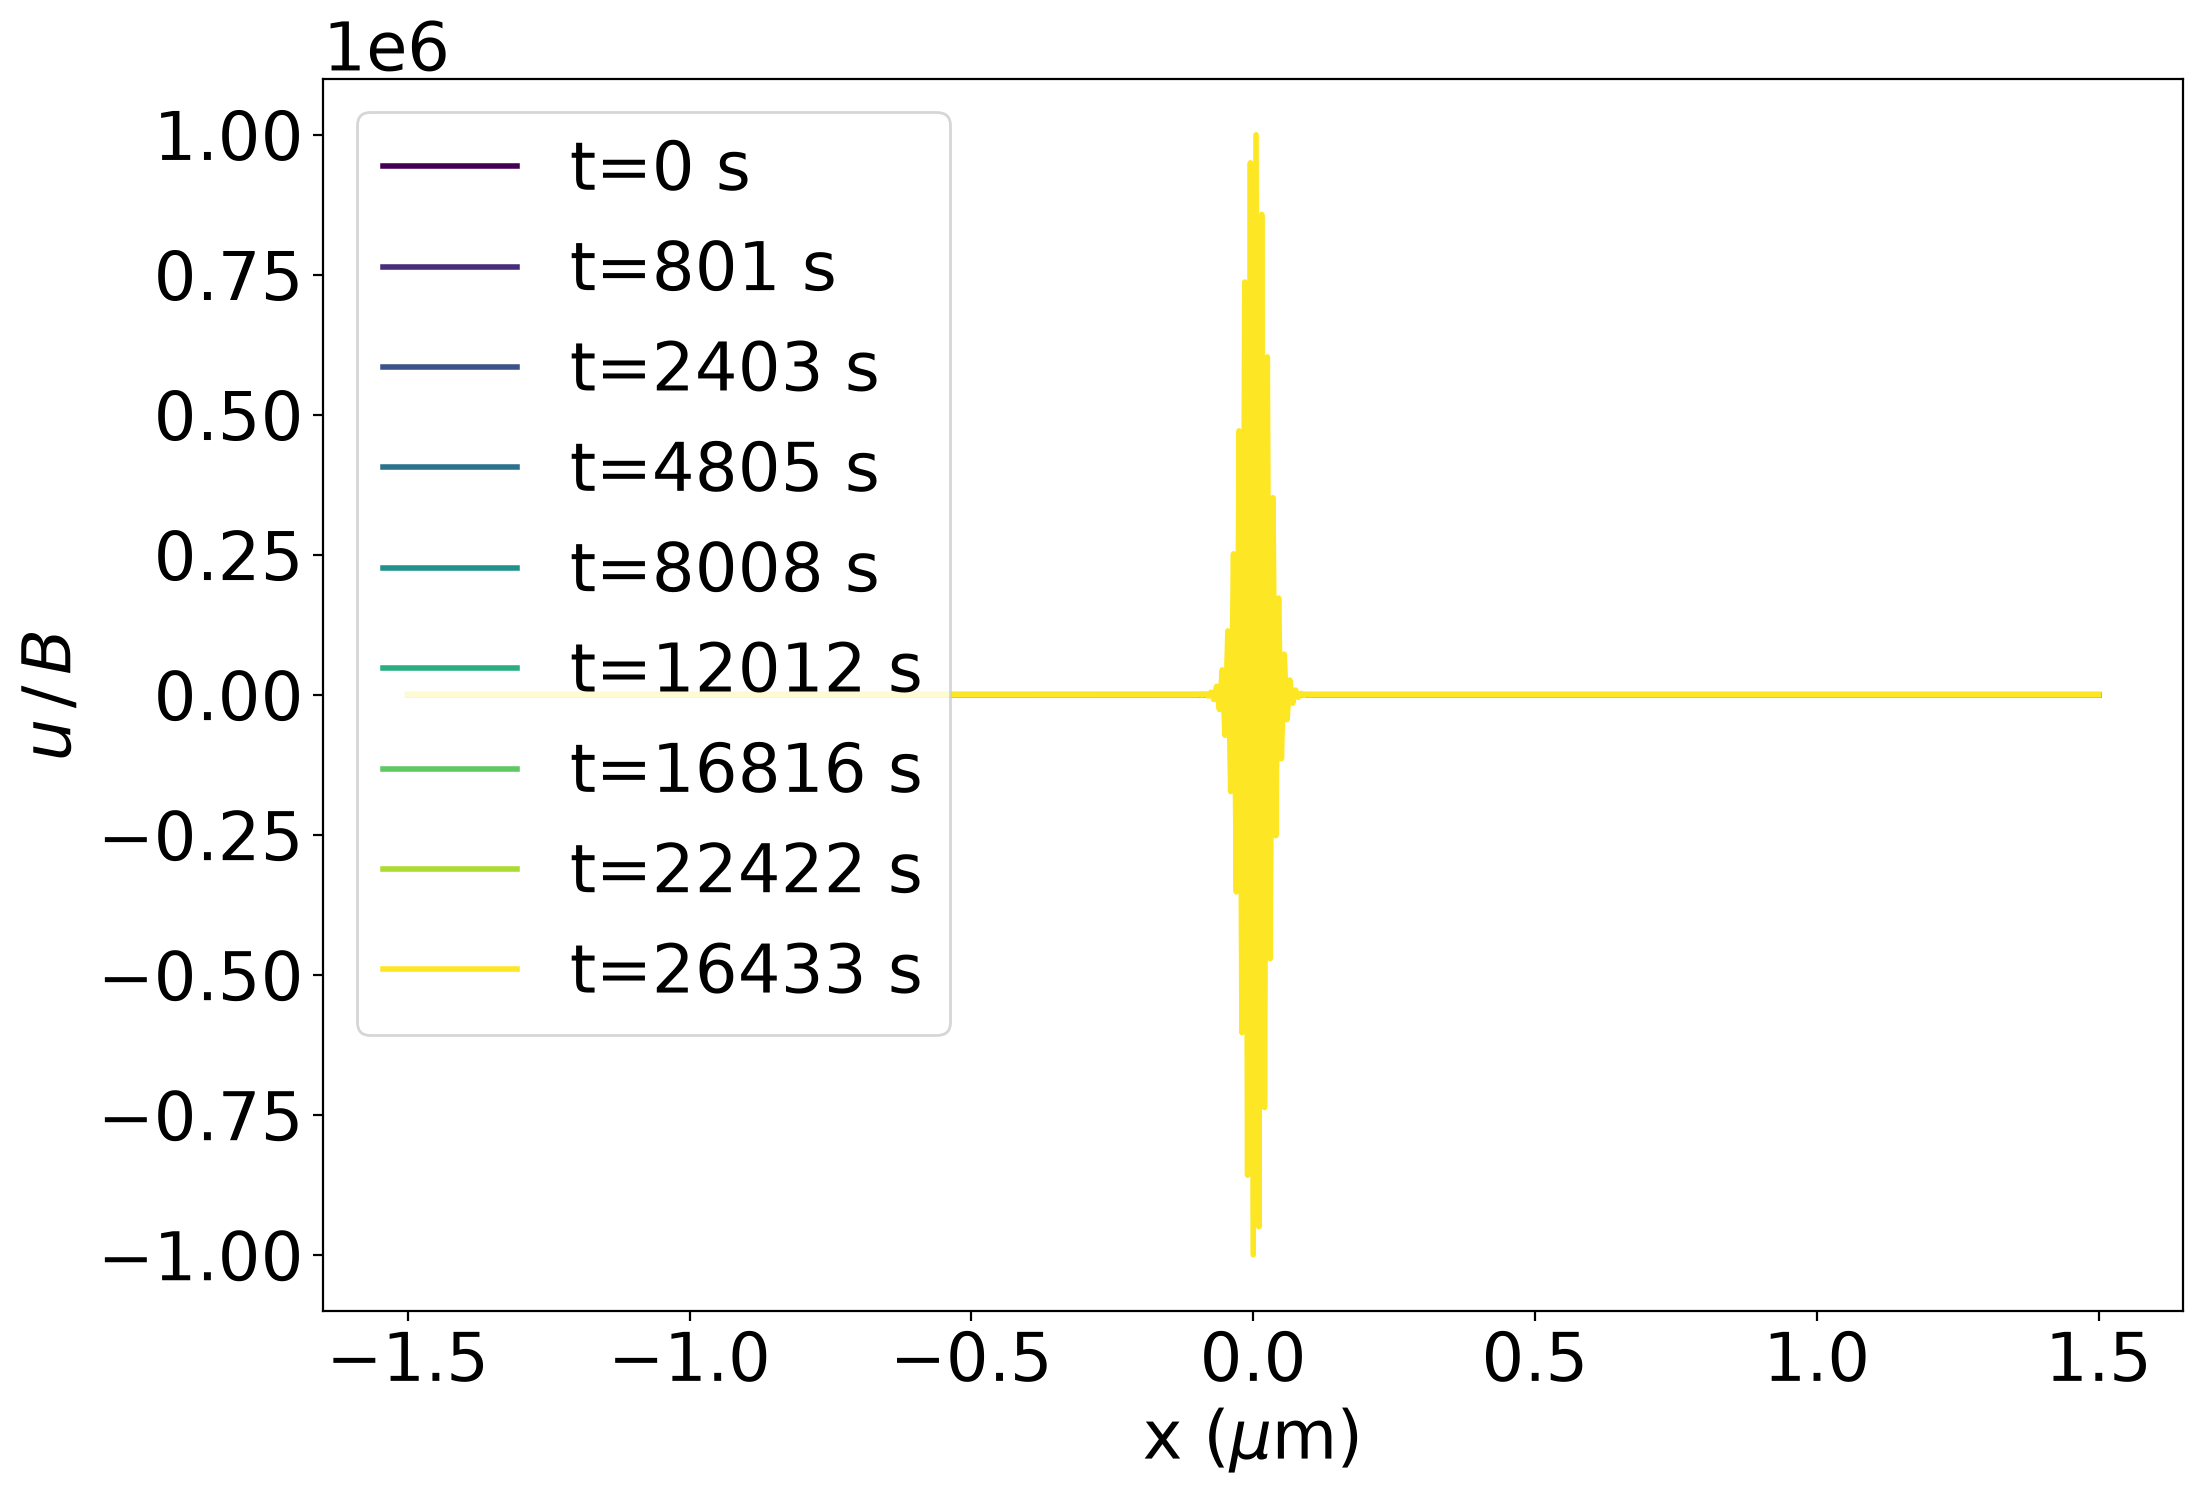

Data file with temp=900.0, Lgb=3.0, dtmax=100000.0


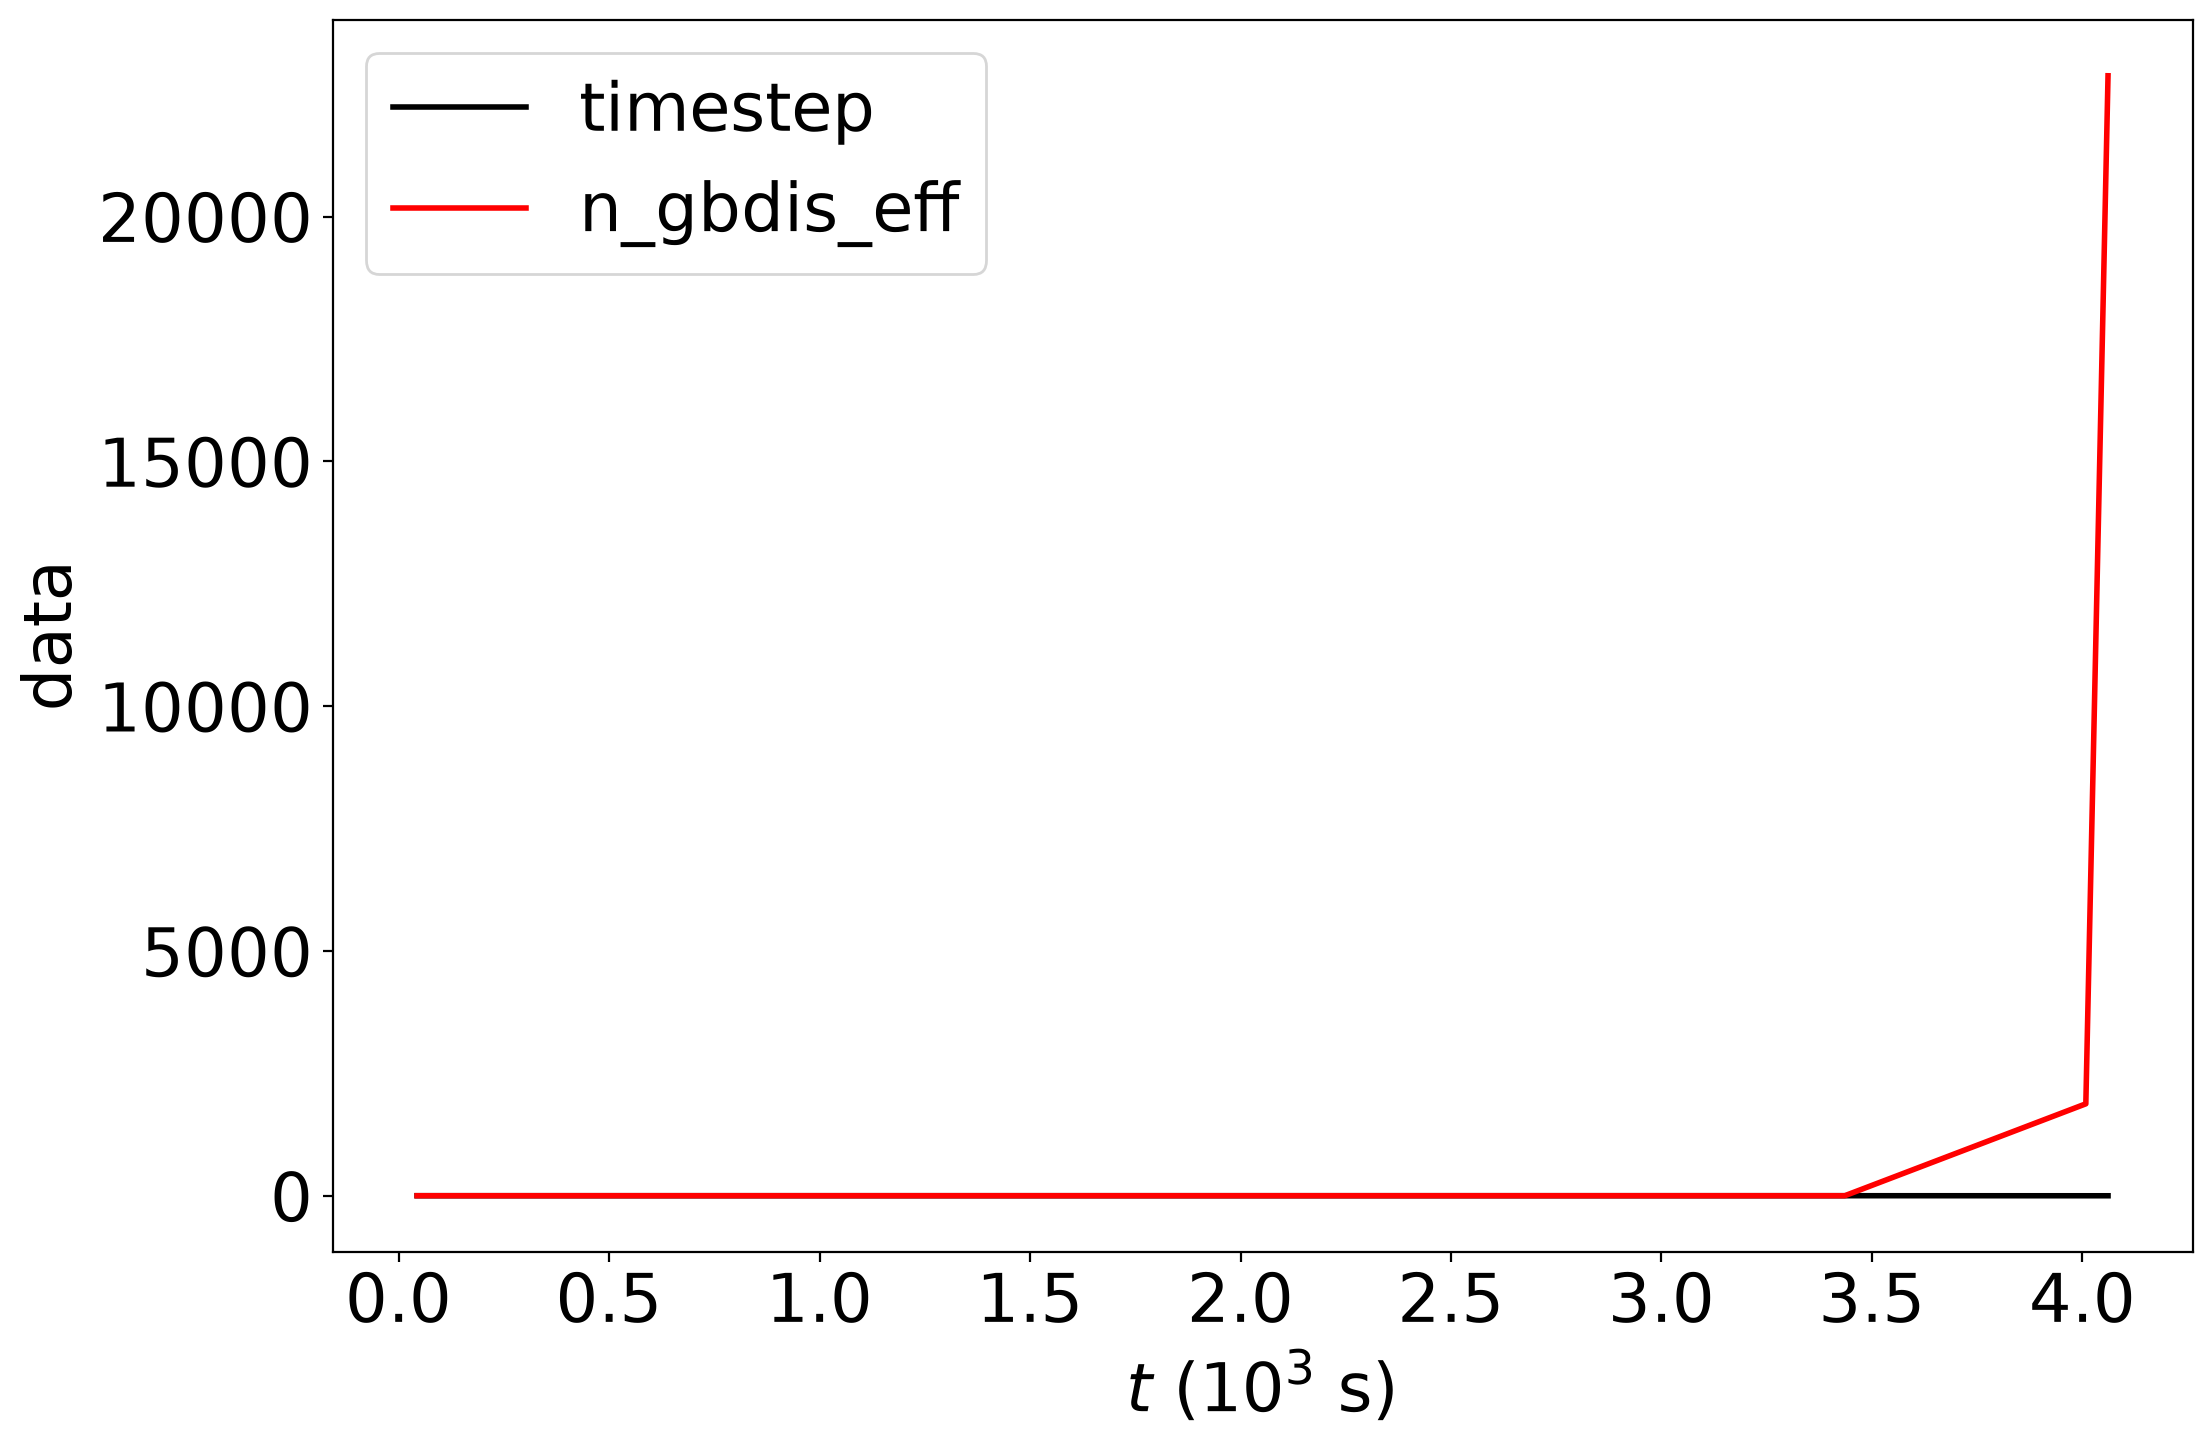

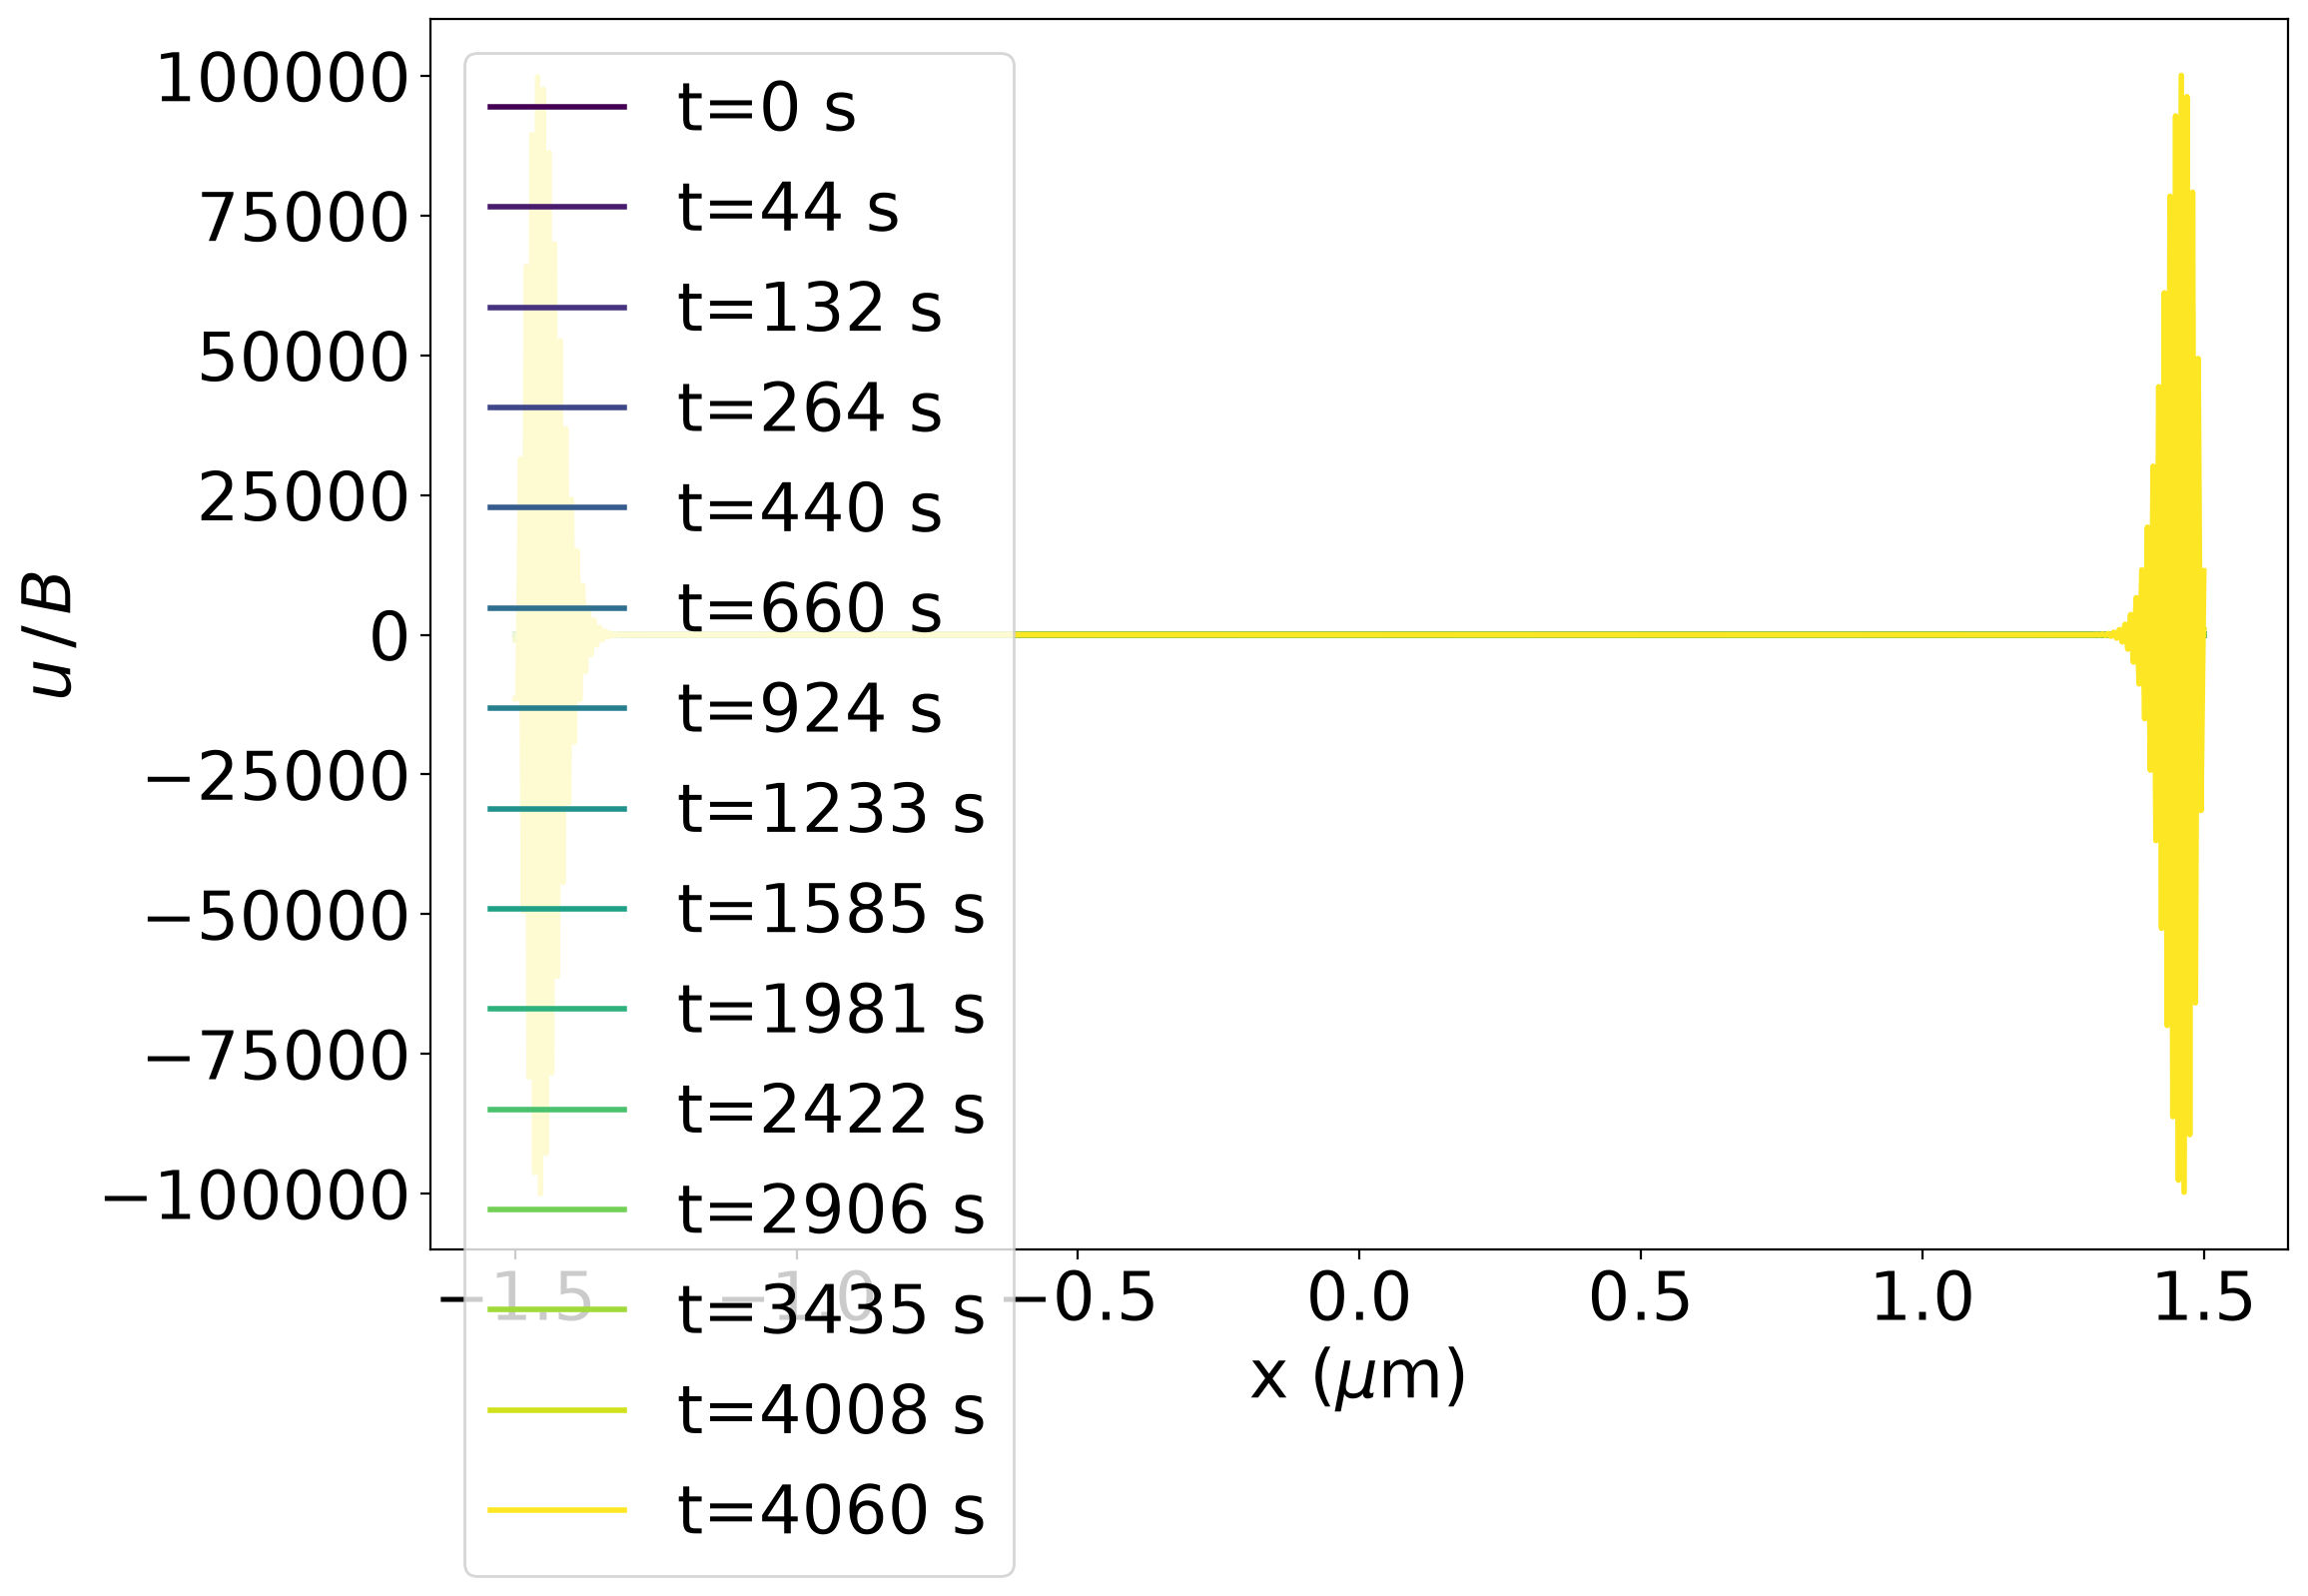

In [12]:
# if result files exits, read them
flist = ["gb1_L3_N61_T600_Q95_dt5", 
         "gb1_L3_N61_T900_Q95_dt5", 
         "gb1_L30_N601_T600_Q95_dt5", 
         "gb1_L30_N601_T900_Q95_dt5"
        ]

for i, fname in enumerate(flist):
    gbdd = dd.GB_dislocations(from_file="../data/resr/"+fname+".h5")
    print(f"Data file with temp={gbdd.temp}, Lgb={gbdd.Dgp}, dtmax={gbdd.dtmax}")
    gbdd.plot_time_series(['timestep', 'n_gbdis_eff'])
    gbdd.plot_field('displacement')
    #gbdd.plot_field('bfield')
    imax = int(np.nonzero(gbdd.sim_time > 3.6e9)[0][0]) # gbdd.nout #
    nit[i] = imax
    Ngb_list[i] = gbdd.Ngbn
    sim_time[i, 0:imax] = gbdd.sim_time[:imax]
    bdmax[i, 0:imax] = gbdd.glob_data['max_bdot'][:imax]
    btot[i, 0:imax] = gbdd.glob_data['n_gbdis_eff'][:imax]
    lgb_list[i] = gbdd.Dgp
    temp_list[i] = gbdd.temp

In [ ]:
np.nonzero(gbdd.sim_time > 3.5e9)[0][0]

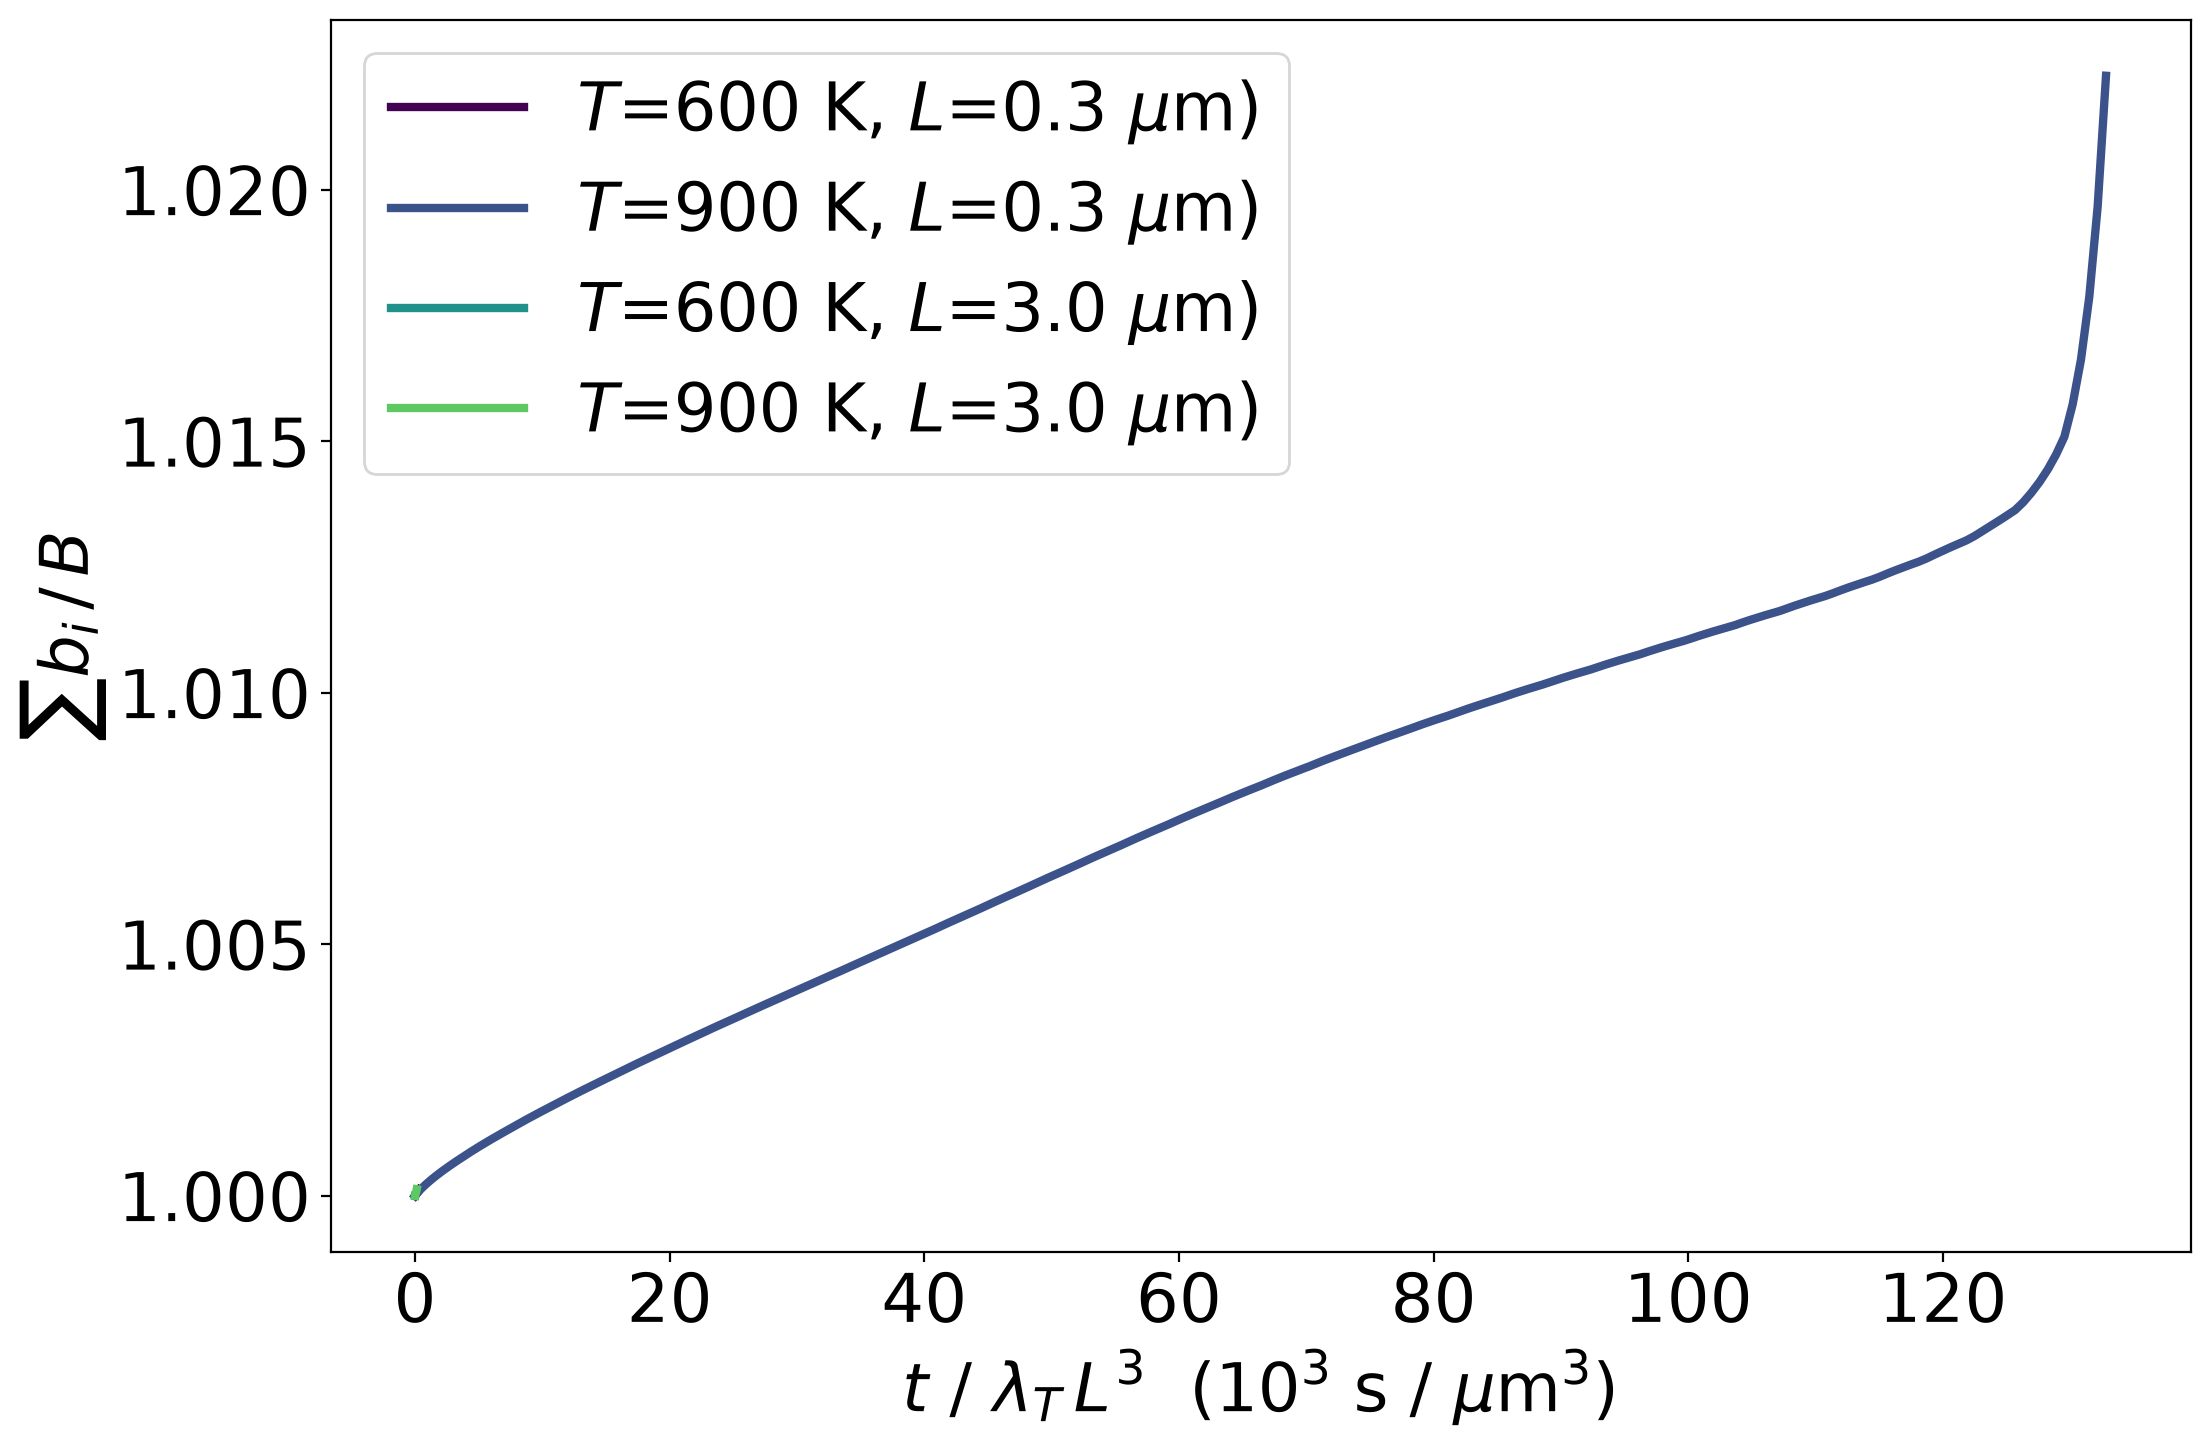

In [13]:
fig, ax = plt.subplots(figsize=(12, 8), dpi=200)
for i in range(Np):
    tr = temp_list[1]/temp_list[i]
    R = 8.31446
    hc = gbdd.Qact / (R*temp_list[1])
    plt.plot(sim_time[i, :nit[i]]*1.e-9*np.exp(hc*(1-tr))*tr / lgb_list[i]**3,
             btot[i, :nit[i]],
             marker="none",
             linestyle="-",
             linewidth=3,
             color=plt.cm.viridis(i / max(1, Np)),
             label=r"$T$" + f"={int(temp_list[i])} K, "+r"$L$" + f"={lgb_list[i]} " + r"$\mu$m)"
             )
plt.legend()
plt.xlabel(r"$t$ / $\lambda_T \, L^3$  (10$^3$ s / $\mu$m$^3$)")
plt.ylabel(r"$\sum b_i \,/ \,B$")
#plt.savefig(f'bres_time_scaled_var_TLgb.pdf', dpi=300, format='pdf')
plt.show()

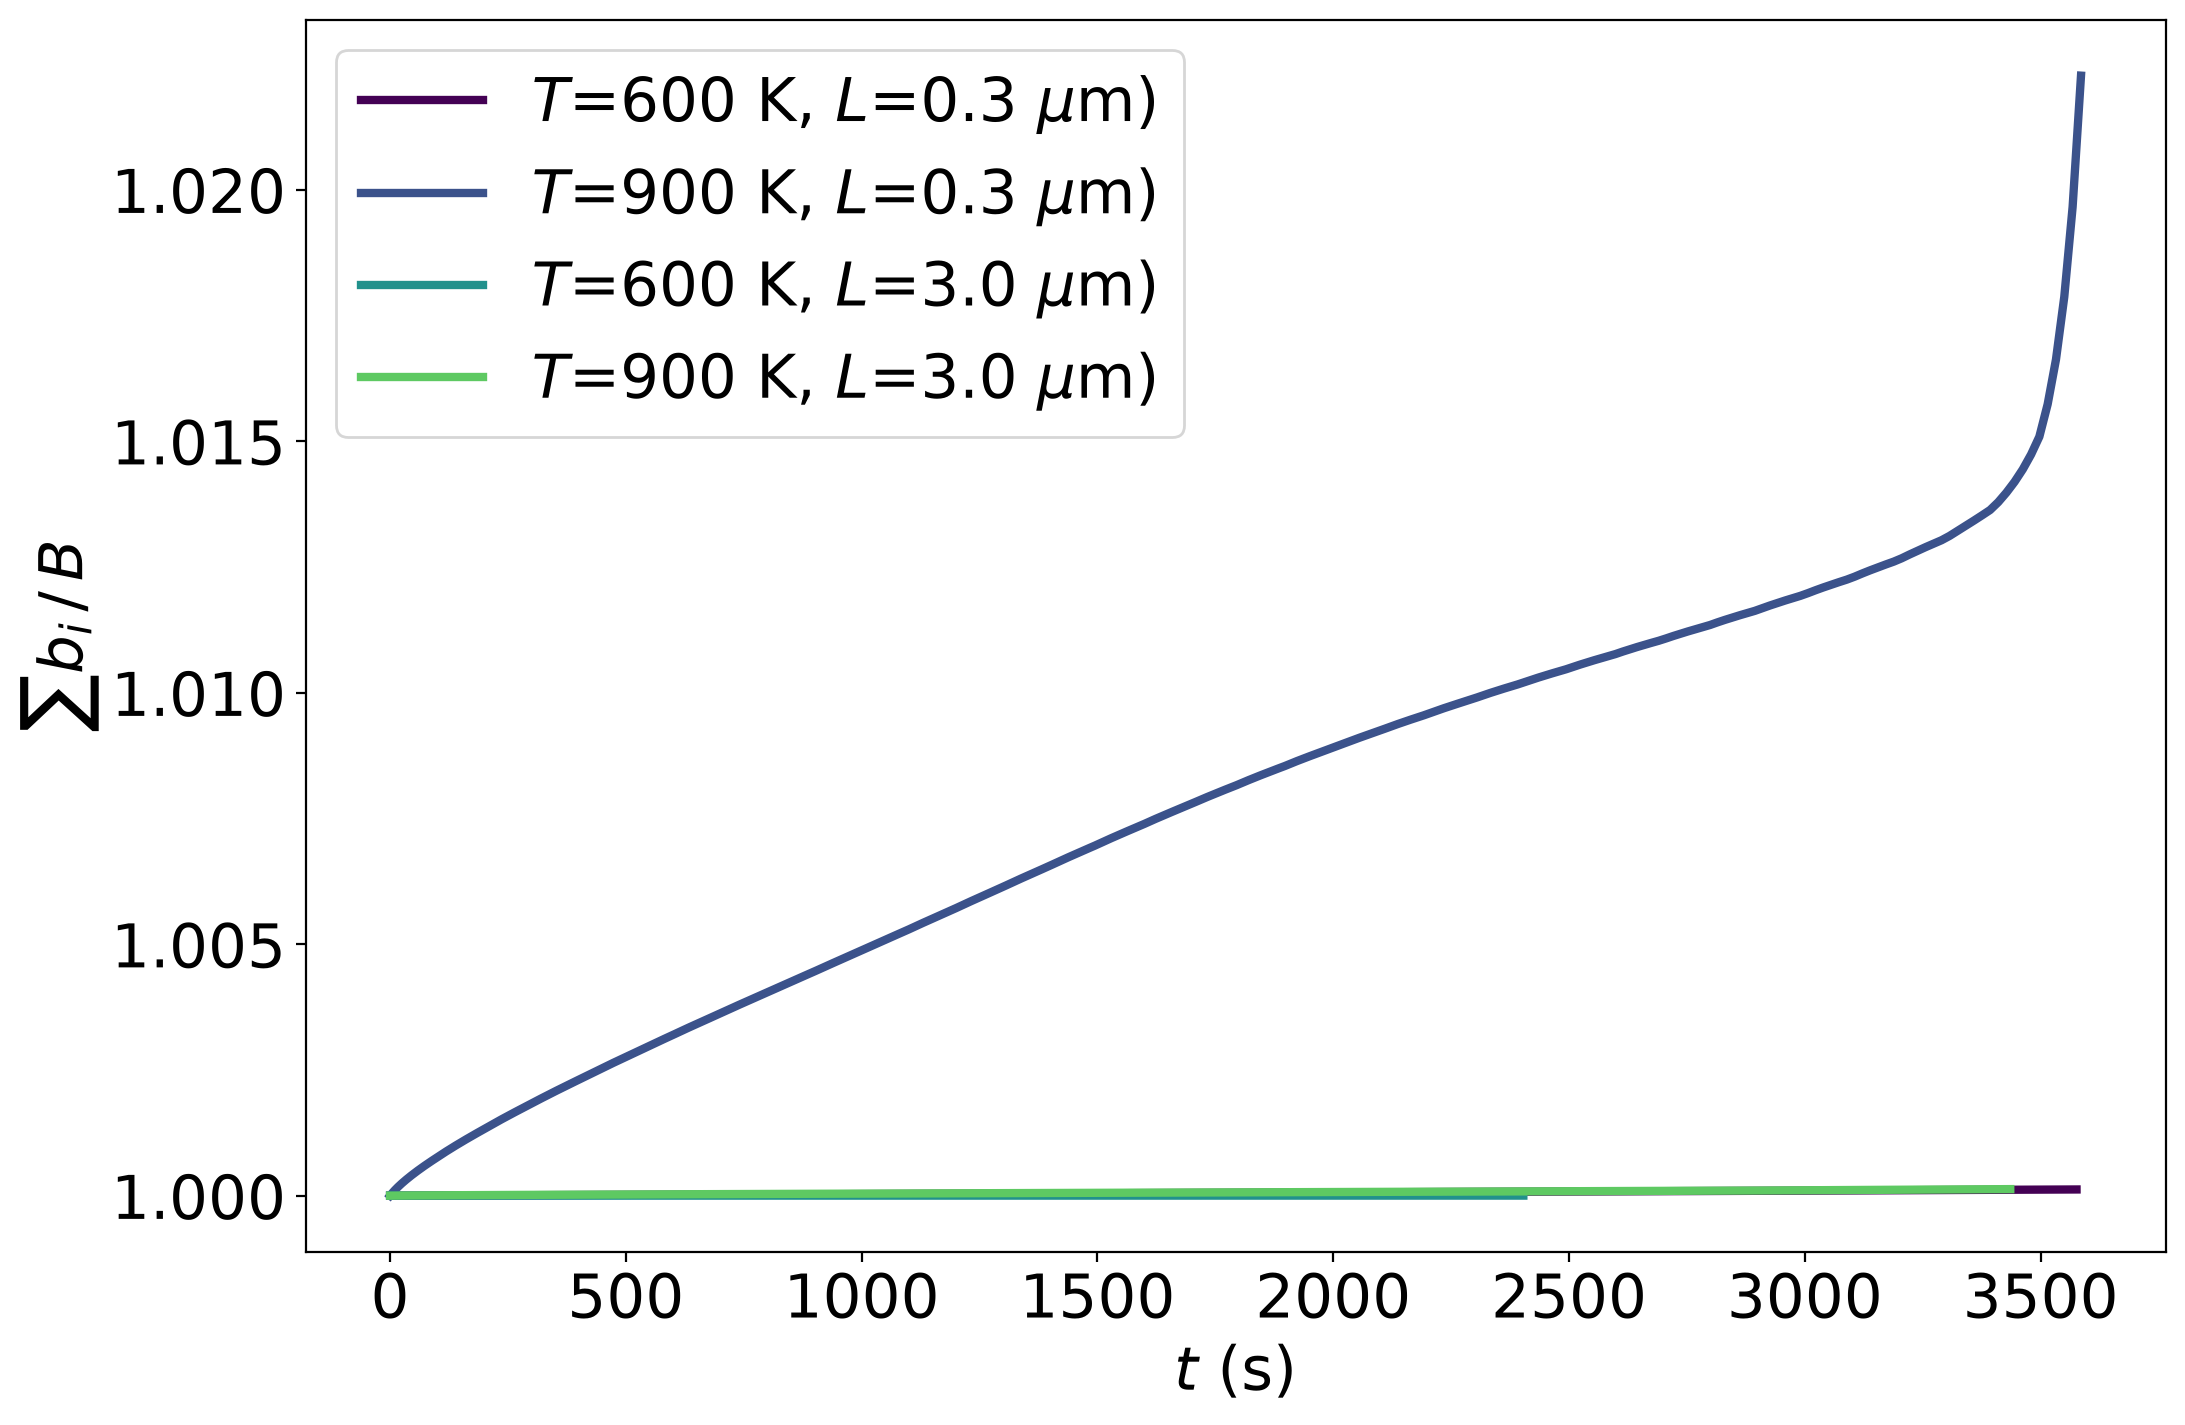

In [14]:
plt.rcParams["font.size"] = 22
fig, ax = plt.subplots(figsize=(12, 8), dpi=200)
for i in range(Np):
    plt.plot(sim_time[i, :nit[i]]*1.e-6,
             btot[i, :nit[i]],
             marker="none",
             linestyle="-",
             linewidth=3,
             color=plt.cm.viridis(i / max(1, Np)),
             label=r"$T$" + f"={int(temp_list[i])} K, "+r"$L$" + f"={lgb_list[i]} " + r"$\mu$m)"
             )
plt.legend()
plt.xlabel(r"$t$ (s)")
plt.ylabel(r"$\sum b_i \,/ \,B$")
#plt.savefig(f'bres_var_TLgb.pdf', dpi=300, format='pdf')
plt.show()

In [ ]:
imax
